# Retrieval cinematografico sui primi 50 film

**Audit delle colonne, ablation study della rappresentazione testuale, BM25, BGE-M3 dense, retrieval ibrido e reranking.**

Questo notebook parte da un DataFrame già disponibile in memoria:

```python
df_test_enriched
```

contenente una riga per film e le colonne MovieLens + TMDb dello schema condiviso.

Lo scopo non è ancora produrre una valutazione conclusiva della tesi: con circa 50 film realizziamo un **test di fattibilità controllato** per scegliere quali colonne usare e verificare l'intera pipeline prima di passare a un catalogo più ampio e a Qdrant.

L'idea è quella di validare le componenti di base del retriever per ridurre confusione nelle fasi successive. In modo da spostarsi con più consapevolezza e sicurezza nella fase successive di gestione delle query verso l'LLM


## Struttura del notebook

1. Configurazione riproducibile e dichiarazione esplicita delle colonne.
2. Audit dello schema, della copertura e della qualità del catalogo.
3. Costruzione di quattro rappresentazioni documentali progressive.
4. Baseline lessicale BM25.
5. Dense retrieval multilingue con BGE-M3.
6. Filtri strutturati su anno, durata, lingua, paese e generi.
7. Fusione BM25 + dense mediante Reciprocal Rank Fusion (RRF).
8. Reranking dei candidati con `bge-reranker-v2-m3`.
9. Griglia di esperimenti sulle diverse rappresentazioni.
10. Pool per giudizi manuali e metriche NDCG@k, Recall@k e Precision@k.

### Decisione metodologica

In questo notebook utilizziamo:

- **un solo vettore dense per film e per rappresentazione sperimentale**;
- BM25 come indice lessicale separato;
- colonne numeriche/categoriche come filtri, non come testo da embeddare;
- rating e popolarità solo come metadata, non come segnali del primo ranking.

BGE-M3 supporta anche sparse retrieval e multi-vector retrieval, ma qui usiamo deliberatamente solo il ramo dense per mantenere leggibile il confronto `BM25 vs dense vs hybrid`.


## 0. Ambiente e dipendenze

È consigliato Google Colab con runtime GPU. I modelli vengono scaricati da Hugging Face alla prima esecuzione.

`FlagEmbedding` implementa sia BGE-M3 sia il reranker. `rank-bm25` fornisce la baseline Okapi BM25. `scikit-learn` viene usato per normalizzare i vettori e per utilità numeriche.

La cella seguente può essere eseguita una volta per runtime. Dopo l'installazione, se Colab lo richiede, riavviare il runtime.


In [ ]:
# %pip install -qU pandas numpy matplotlib seaborn scikit-learn rank-bm25 FlagEmbedding


In [2]:
import os
from datetime import datetime

# DEVE ESSERE LA PRIMA COSA IN ASSOLUTO NEL FILE
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "0"  # Disattiva altri acceleratori che si bloccano


from __future__ import annotations

import importlib.metadata as importlib_metadata
import math
import re
import warnings
from pathlib import Path
from typing import Any, Iterable, Mapping, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from rank_bm25 import BM25Okapi
from sklearn.preprocessing import normalize as l2_normalize
import FlagEmbedding


pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

for package_name in [
    "pandas",
    "numpy",
    "scikit-learn",
    "rank-bm25",
    "FlagEmbedding",
    "torch",
]:
    try:
        print(f"{package_name}: {importlib_metadata.version(package_name)}")
    except importlib_metadata.PackageNotFoundError:
        print(f"{package_name}: versione non rilevata")

print("CUDA disponibile:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


pandas: 3.0.5
numpy: 2.5.1
scikit-learn: 1.9.0
rank-bm25: 0.2.2
FlagEmbedding: 1.4.2
torch: 2.13.0
CUDA disponibile: False


## 1. Configurazione centrale: colonne e rappresentazioni

Questa è la sezione principale da modificare quando si vuole riprovare l'esperimento con colonne diverse.

Ogni rappresentazione è una lista ordinata di coppie:

```python
(etichetta leggibile nel documento, nome della colonna nel DataFrame)
```

Le rappresentazioni sono progressive:

- **A — overview:** titolo e sinossi;
- **B — semantic core:** aggiunge generi e keyword TMDb;
- **C — + MovieLens tags:** misura il contributo dei tag degli utenti;
- **D — full enriched:** aggiunge tagline, persone, personaggi, collection e aziende.

Anno, durata, lingua, paesi e generi rimangono disponibili anche come filtri strutturati. Rating, vote count e popolarità non entrano nei documenti.


In [ ]:
# ------------------------------
# Identificativi e colonne base
# ------------------------------
ID_COLUMN = "movieId"
TITLE_COLUMN = "tmdb_title" #"canonical_title"
EXPECTED_N_FILMS = 2000

# Se df_test_enriched non è già in memoria, il notebook prova questo file.
# Modificare liberamente il percorso oppure lasciare il DataFrame già caricato.
CSV_FALLBACK_PATH = Path("single_dataset_enriched_movielens_tmdb.csv")


# Definizione percorsi
PROJECT_ROOT = Path('..')
DATA_RAW = PROJECT_ROOT / 'datasets' / 'raw' / 'ml-latest-small'
DATA_PROCESSED = PROJECT_ROOT / 'datasets' / 'processed'

#recupero dataframe con cui lavorare
final_outputs = sorted(DATA_PROCESSED.glob('dataset_enriched_movielens_tmdb*'), key=os.path.getmtime, reverse=True)

print(f"\n📁 Output finali: {len(final_outputs)}")
for f in final_outputs:
    size_mb = f.stat().st_size / (1024*1024)
    mtime = datetime.fromtimestamp(f.stat().st_mtime).strftime('%Y-%m-%d %H:%M:%S')
    print(f"  - {f.name} ({size_mb:.2f} MB, mod: {mtime})")

try:
    # Carica DF dati
    movies_files = list(DATA_PROCESSED.glob('dataset_enriched_movielens_tmdb.csv'))
    assert len(movies_files) > 0, "Nessun movies_enriched trovato"
    df_test_enriched = pd.read_csv(movies_files[0])
    assert len(df_test_enriched) > 0, "Dataset merged vuoto"
    print("✓ Test 2: Dataset merged caricato con successo")
    
    # Test 1: verifico unicità DF
    assert df_test_enriched['movieId'].nunique() == len(df_test_enriched), "movieId non unique"
    print("✓ Test 1: movieId unique")
    
    print("\nDati caricati pronti all'untilizzo")
    
except Exception as e:
    print(f"\n✗ ERRORE lettura dati: {e}")


# ------------------------------
# Ablation study: testo da indicizzare/vettorizzare
# ------------------------------

# MODEL_TYPE = {
#     'A_overview':"A_overview",
#     'B_semantic_core': 'B_semantic_core',
#     'C_plus_movielens_tags': 'C_plus_movielens_tags',
#     'D_full_enriched': 'D_full_enriched',
# }

#TODO: sarebbe meglio usare tmdb_title? esempio:
# canonical_title	    ml_title	        tmdb_title
# Toy Story (1995)	    Toy Story (1995)	Toy Story

DOCUMENT_EXPERIMENTS: dict[str, dict[str, Any]] = {
    "A_overview": {
        "description": "Titolo + overview (baseline semantica minima)",
        "fields": [
            ("Title", "tmdb_title"),
            ("Overview", "overview"),
        ],
    },
    "B_semantic_core": {
        "description": "Titolo + generi + overview + keyword TMDb",
        "fields": [
            ("Title", "tmdb_title"),
            # ("MovieLens genres", "ml_genres"),
            ("genres", "tmdb_genres"),
            ("Overview", "overview"),
            ("keywords", "tmdb_keyword_text"),
        ],
    },
    "C_plus_movielens_tags": {
        "description": "Semantic core + tag MovieLens",
        "fields": [
            ("Title", "tmdb_title"),
            # ("MovieLens genres", "ml_genres"),
            ("genres", "tmdb_genres"),
            ("Overview", "overview"),
            ("keywords", "tmdb_keyword_text"),
            ("user tags", "ml_tags"),
        ],
    },
    "D_full_enriched": {
        "description": "Semantic core + tag + persone/personaggi/collection/aziende",
        "fields": [
            ("Title", "tmdb_title"),
            # ("MovieLens genres", "ml_genres"),
            ("genres", "tmdb_genres"),
            ("Overview", "overview"),
            ("Tagline", "tagline"),
            ("keywords", "tmdb_keyword_text"),
            ("user tags", "ml_tags"),
            ("Directors", "directors"),
            ("Writers", "writers"),
            ("Composers", "composers"),
            ("Main cast", "cast_top"),
            ("Main characters", "cast_characters_top"),
            ("Collection", "collection_name"),
            ("Production companies", "production_companies"),
        ],
    },
}

# Colonne che hanno soprattutto un ruolo lessicale/di entità.
# Sono già presenti nella configurazione D, ma vengono dichiarate separatamente
# per rendere esplicita la loro funzione metodologica.
LEXICAL_ENTITY_COLUMNS = [
    "canonical_title",
    "ml_title",
    "tmdb_title",
    "tmdb_original_title",
    "tmdb_keyword_text",
    "ml_tags",
    "directors",
    "writers",
    "composers",
    "cast_top",
    "cast_characters_top",
    "collection_name",
    "production_companies",
]

# Queste colonne vengono usate per condizioni esatte, non affidate agli embedding.
FILTER_COLUMNS = [
    "release_year",
    "runtime",
    "original_language",
    "origin_countries",
    "production_countries",
    "ml_genres",
    "tmdb_genres",
    "adult",
]

# Metadata conservati, ma esclusi dal primo ranking per evitare popularity bias.
METADATA_ONLY_COLUMNS = [
    "ml_rating_mean",
    "ml_rating_count",
    "ml_rating_std",
    "ml_unique_users",
    "ml_weighted_rating",
    "tmdb_vote_average",
    "tmdb_vote_count",
    "tmdb_popularity",
    "budget",
    "revenue",
]

# ------------------------------
# Modelli e parametri di retrieval
# ------------------------------
EMBEDDING_MODEL_NAME = "BAAI/bge-m3"
RERANKER_MODEL_NAME = "BAAI/bge-reranker-v2-m3"

LOAD_DENSE_MODEL = True
LOAD_RERANKER_MODEL = True
USE_FP16 = bool(torch.cuda.is_available())

EMBEDDING_BATCH_SIZE = 16
DOCUMENT_MAX_LENGTH = 1024
QUERY_MAX_LENGTH = 512

TOP_K = 10 #10
CANDIDATE_POOL_SIZE = 20 #20

RRF_K = 60
BM25_RRF_WEIGHT = 0.5
DENSE_RRF_WEIGHT = 0.5

print("Esperimenti configurati:")
for experiment_name, config in DOCUMENT_EXPERIMENTS.items():
    columns = [column for _, column in config["fields"]]
    print(f"- {experiment_name}: {columns}")



📁 Output finali: 2
  - dataset_enriched_movielens_tmdb.csv (0.17 MB, mod: 2026-09-01 12:13:57)
  - dataset_enriched_movielens_tmdb.parquet (0.16 MB, mod: 2026-07-29 15:41:49)
✓ Test 2: Dataset merged caricato con successo
✓ Test 1: movieId unique

Dati caricati pronti all'untilizzo
Esperimenti configurati:
- A_overview: ['canonical_title', 'overview']
- B_semantic_core: ['canonical_title', 'tmdb_genres', 'overview', 'tmdb_keyword_text']
- C_plus_movielens_tags: ['canonical_title', 'tmdb_genres', 'overview', 'tmdb_keyword_text', 'ml_tags']
- D_full_enriched: ['canonical_title', 'tmdb_genres', 'overview', 'tagline', 'tmdb_keyword_text', 'ml_tags', 'directors', 'writers', 'composers', 'cast_top', 'cast_characters_top', 'collection_name', 'production_companies']


## 2. Recupero di `df_test_enriched`

La cella mantiene il DataFrame già presente in memoria. Il fallback CSV serve solo a rendere il notebook autonomo.

Non imponiamo rigidamente 50 righe: mostriamo un warning, perché il CSV di esempio o un sottoinsieme di debug possono contenerne meno.


In [7]:
if "df_test_enriched" not in globals():
    if CSV_FALLBACK_PATH.exists():
        df_test_enriched = pd.read_csv(CSV_FALLBACK_PATH)
        print(f"DataFrame caricato da: {CSV_FALLBACK_PATH.resolve()}")
    else:
        raise RuntimeError(
            "df_test_enriched non è presente in memoria e il CSV di fallback non esiste. "
            "Caricare prima il DataFrame oppure modificare CSV_FALLBACK_PATH."
        )
else:
    print("Uso df_test_enriched già presente in memoria.")

if not isinstance(df_test_enriched, pd.DataFrame):
    raise TypeError("df_test_enriched deve essere un pandas.DataFrame")

# Reset dell'indice: tutte le matrici e gli indici useranno posizioni 0..N-1.
retrieval_df = df_test_enriched.copy().reset_index(drop=True)

print("Shape:", retrieval_df.shape)
if len(retrieval_df) != EXPECTED_N_FILMS:
    warnings.warn(
        f"Attesi circa {EXPECTED_N_FILMS} film per questo test, trovati {len(retrieval_df)}. "
        "Il notebook continua comunque."
    )

display(retrieval_df.head(3))


Uso df_test_enriched già presente in memoria.
Shape: (50, 52)


,movieId,imdbId,tmdbId,canonical_title,ml_title,tmdb_title,tmdb_original_title,release_date,release_year,ml_genres,tmdb_genres,ml_tags,ml_tag_weights,ml_tag_text,ml_tag_application_count,ml_unique_tag_count,tmdb_keywords,tmdb_keyword_text,tmdb_keyword_count,overview,tagline,runtime,original_language,origin_countries,production_countries,spoken_languages,adult,directors,writers,composers,cast_top,cast_characters_top,collection_name,production_companies,ml_rating_mean,ml_rating_count,ml_rating_std,ml_unique_users,ml_weighted_rating,tmdb_vote_average,tmdb_vote_count,tmdb_popularity,budget,revenue,poster_path,backdrop_path,homepage,tmdb_enrichment_status,tmdb_retrieved_at,text_movielens,text_tmdb,text_combined
0,356,109830,13,Forrest Gump (1994),Forrest Gump (1994),Forrest Gump,Forrest Gump,1994-06-23,1994,Comedy|Drama|Romance|War,"Comedy, Drama, Romance","Vietnam, bittersweet, bubba gump shrimp, emotional, heartwarming, lieutenant dan, shrimp, stupid is as stupid does, touching",shrimp:1|Vietnam:1|bubba gump shrimp:1|lieutenant dan:1|stupid is as stupid does:1|bittersweet:1|emotional:1|heartwarming:1|touching:1,shrimp vietnam bubba gump shrimp lieutenant dan stupid is as stupid does bittersweet emotional heartwarming touching,9.0,9.0,"new year's eve, vietnam war, vietnam veteran, mentally disabled, friendship, usa president, washington dc, usa, post-traumatic stress di...","new year's eve vietnam war vietnam veteran mentally disabled friendship usa president washington dc, usa post-traumatic stress disorder ...",32,"A man with a low IQ has accomplished great things in his life and been present during significant historic events—in each case, far exce...",The world will never be the same once you've seen it through the eyes of Forrest Gump.,142,en,US,US,en,False,Robert Zemeckis,Eric Roth,Alan Silvestri,"Tom Hanks, Robin Wright, Gary Sinise, Sally Field, Mykelti Williamson","Forrest Gump, Jenny Curran, Lieutenant Dan Taylor, Mrs. Gump, Bubba Blue",NaN,"Paramount Pictures, The Steve Tisch Company, Wendy Finerman Productions",4.164134,329,0.831244,329,4.153303,8.464,30056,36.8104,55000000,677387716,/Cw4hIUIAmSYfK9QfaUW5igp9La.jpg,/66Kn4XWhkuPkJxOJyPEx4U2CUfN.jpg,https://www.paramountmovies.com/movies/forrest-gump,ok,2026-07-29T15:41:49,Forrest Gump (1994) Comedy|Drama|Romance|War shrimp vietnam bubba gump shrimp lieutenant dan stupid is as stupid does bittersweet emotio...,"A man with a low IQ has accomplished great things in his life and been present during significant historic events—in each case, far exce...",Forrest Gump (1994) Comedy|Drama|Romance|War shrimp vietnam bubba gump shrimp lieutenant dan stupid is as stupid does bittersweet emotio...
1,318,111161,278,"Shawshank Redemption, The (1994)","Shawshank Redemption, The (1994)",The Shawshank Redemption,The Shawshank Redemption,1994-09-23,1994,Crime|Drama,"Drama, Crime","Morgan Freeman, Stephen King, prison, wrongful imprisonment",prison:1|Stephen King:1|wrongful imprisonment:1|Morgan Freeman:1,prison stephen king wrongful imprisonment morgan freeman,4.0,4.0,"prison, friendship, police brutality, corruption, based on novel or book, freedom, hope, prison cell, delinquent, redemption, parole boa...",prison friendship police brutality corruption based on novel or book freedom hope prison cell delinquent redemption parole board prison ...,18,"Imprisoned in the 1940s for the double murder of his wife and her lover, upstanding banker Andy Dufresne begins a new life at the Shawsh...",Fear can hold you prisoner. Hope can set you free.,142,en,US,US,en,False,Frank Darabont,Frank Darabont,Thomas Newman,"Tim Robbins, Morgan Freeman, Bob Gunton, William Sadler, Clancy Brown","Andy Dufresne, Ellis Boyd 'Red' Redding, Warden Norton, Heywood, Captain Byron T. Hadley",NaN,Castle Rock Entertainment,4.429022,317,0.713019,317,4.414485,8.726,30872,114.2776,25000000,28341469,/9cqNxx0GxF0bflZmeSMuL5tnGzr.jpg,/zfbjgQE1uSd9wiPTX4VzsLi0rGG.jpg,NaN,ok,2026-07-29T15:41:49,"Shawshank Redemption, The (1994)

## 3. Audit dello schema e della copertura

Prima di produrre embedding controlliamo:

- presenza delle colonne dichiarate;
- tipo Pandas;
- valori non nulli e non vuoti;
- copertura percentuale;
- cardinalità;
- un esempio compatto.

Una colonna assente non viene nascosta: appare esplicitamente nell'audit. Solo identificativo e titolo sono considerati indispensabili.


In [8]:
REQUIRED_COLUMNS = [ID_COLUMN, TITLE_COLUMN]

experiment_columns = {
    column
    for config in DOCUMENT_EXPERIMENTS.values()
    for _, column in config["fields"]
}
ALL_REFERENCED_COLUMNS = sorted(
    set(REQUIRED_COLUMNS)
    | experiment_columns
    | set(LEXICAL_ENTITY_COLUMNS)
    | set(FILTER_COLUMNS)
    | set(METADATA_ONLY_COLUMNS)
)

missing_required = [c for c in REQUIRED_COLUMNS if c not in retrieval_df.columns]
if missing_required:
    raise KeyError(f"Colonne indispensabili mancanti: {missing_required}")


def non_empty_mask(series: pd.Series) -> pd.Series:
    return series.notna() & series.astype(str).str.strip().ne("")


audit_rows = []
for column in ALL_REFERENCED_COLUMNS:
    if column in retrieval_df.columns:
        mask = non_empty_mask(retrieval_df[column])
        example_values = retrieval_df.loc[mask, column].astype(str)
        audit_rows.append(
            {
                "column": column,
                "exists": True,
                "dtype": str(retrieval_df[column].dtype),
                "non_empty": int(mask.sum()),
                "coverage_pct": round(100 * mask.mean(), 1),
                "n_unique": int(retrieval_df.loc[mask, column].nunique()),
                "example": example_values.iloc[0][:120] if len(example_values) else "",
            }
        )
    else:
        audit_rows.append(
            {
                "column": column,
                "exists": False,
                "dtype": None,
                "non_empty": 0,
                "coverage_pct": 0.0,
                "n_unique": 0,
                "example": "",
            }
        )

schema_audit = pd.DataFrame(audit_rows)
display(schema_audit)


,column,exists,dtype,non_empty,coverage_pct,n_unique,example
0,adult,True,bool,50,100.0,1,False
1,budget,True,int64,50,100.0,37,55000000
2,canonical_title,True,str,50,100.0,50,Forrest Gump (1994)
3,cast_characters_top,True,str,50,100.0,49,"Forrest Gump, Jenny Curran, Lieutenant Dan Taylor, Mrs. Gump, Bubba Blue"
4,cast_top,True,str,50,100.0,48,"Tom Hanks, Robin Wright, Gary Sinise, Sally Field, Mykelti Williamson"
5,collection_name,True,str,33,66.0,28,The Hannibal Lecter Collection
6,composers,True,str,49,98.0,31,Alan Silvestri
7,directors,True,str,50,100.0,39,Robert Zemeckis
8,ml_genres,True,str,50,100.0,40,Comedy|Drama|Romance|War
9,ml_rating_count,True,int64,50,100.0,43,329


In [92]:
# Mappa leggibile esperimento -> colonne, nell'ordine effettivo di serializzazione.
experiment_field_rows = []
coverage_by_column = schema_audit.set_index("column")["coverage_pct"].to_dict()

for experiment_name, config in DOCUMENT_EXPERIMENTS.items():
    for order, (label, column) in enumerate(config["fields"], start=1):
        experiment_field_rows.append(
            {
                "experiment": experiment_name,
                "description": config["description"],
                "order": order,
                "label": label,
                "column": column,
                "exists": column in retrieval_df.columns,
                "coverage_pct": coverage_by_column.get(column, 0.0),
            }
        )

experiment_field_table = pd.DataFrame(experiment_field_rows)
display(experiment_field_table)


,experiment,description,order,label,column,exists,coverage_pct
0,A_overview,Titolo + overview (baseline semantica minima),1,Title,canonical_title,True,100.0
1,A_overview,Titolo + overview (baseline semantica minima),2,Overview,overview,True,100.0
2,B_semantic_core,Titolo + generi + overview + keyword TMDb,1,Title,canonical_title,True,100.0
3,B_semantic_core,Titolo + generi + overview + keyword TMDb,2,genres,tmdb_genres,True,100.0
4,B_semantic_core,Titolo + generi + overview + keyword TMDb,3,Overview,overview,True,100.0
5,B_semantic_core,Titolo + generi + overview + keyword TMDb,4,keywords,tmdb_keyword_text,True,100.0
6,C_plus_movielens_tags,Semantic core + tag MovieLens,1,Title,canonical_title,True,100.0
7,C_plus_movielens_tags,Semantic core + tag MovieLens,2,genres,tmdb_genres,True,100.0
8,C_plus_movielens_tags,Semantic core + tag MovieLens,3,Overview,overview,True,100.0
9,C_plus_movielens_tags,Semantic core + tag MovieLens,4,keywords,tmdb_keyword_text,True,100.0


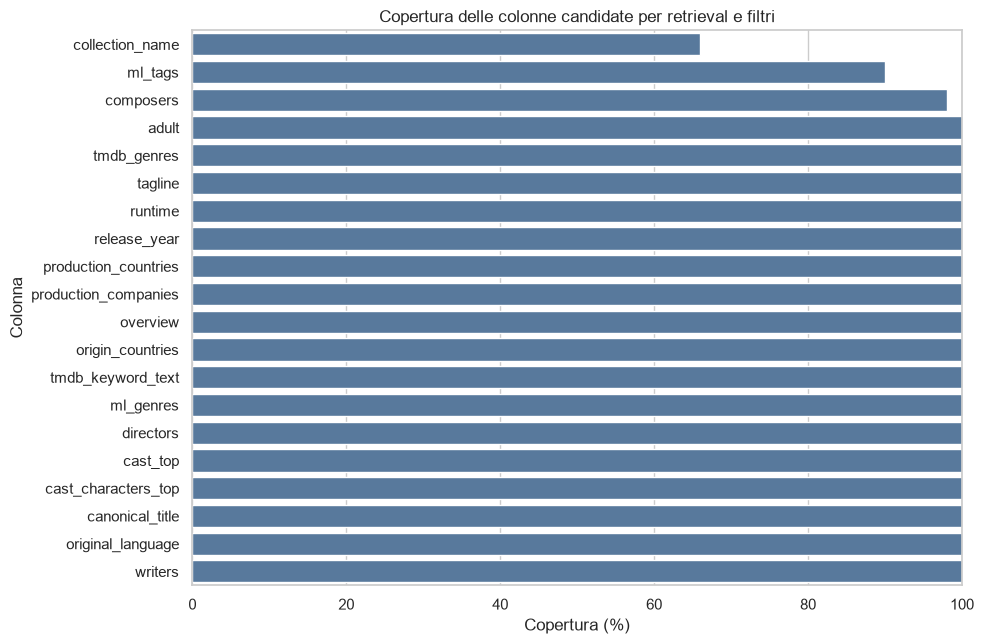

In [10]:
# Copertura delle sole colonne candidate per retrieval e filtro.
plotted_columns = sorted(experiment_columns | set(FILTER_COLUMNS))
coverage_plot_df = (
    schema_audit[schema_audit["column"].isin(plotted_columns)]
    .sort_values("coverage_pct", ascending=True)
)

plt.figure(figsize=(10, max(5, 0.33 * len(coverage_plot_df))))
sns.barplot(data=coverage_plot_df, x="coverage_pct", y="column", color="#4C78A8")
plt.xlim(0, 100)
plt.xlabel("Copertura (%)")
plt.ylabel("Colonna")
plt.title("Copertura delle colonne candidate per retrieval e filtri")
plt.tight_layout()
plt.show()


In [11]:
# Controlli di qualità che potrebbero invalidare gli esperimenti.
duplicate_ids = retrieval_df[retrieval_df.duplicated(ID_COLUMN, keep=False)]
duplicate_titles = retrieval_df[retrieval_df.duplicated(TITLE_COLUMN, keep=False)]

print("ID duplicati:", len(duplicate_ids))
if len(duplicate_ids):
    display(duplicate_ids[[ID_COLUMN, TITLE_COLUMN]].sort_values(ID_COLUMN))

print("Titoli duplicati:", len(duplicate_titles))
if len(duplicate_titles):
    display(duplicate_titles[[ID_COLUMN, TITLE_COLUMN]].sort_values(TITLE_COLUMN))

if retrieval_df[ID_COLUMN].isna().any():
    raise ValueError(f"La colonna {ID_COLUMN} contiene valori nulli")
if retrieval_df[ID_COLUMN].duplicated().any():
    raise ValueError(f"La colonna {ID_COLUMN} deve identificare univocamente i film")

print("Controlli sugli identificativi superati.")


ID duplicati: 0
Titoli duplicati: 0
Controlli sugli identificativi superati.


## 4. Costruzione controllata dei documenti

Non concatenamo valori anonimi. Ogni campo viene serializzato su una riga con un'etichetta:

```text
Title: Arrival (2016)
genres: Science Fiction, Drama
Overview: ...
keywords: first contact, alien language, nonlinear time
```

Le etichette rendono il documento ispezionabile e conservano il ruolo semantico del campo. I valori mancanti vengono saltati senza inserire stringhe come `nan` o `None`.


In [12]:
NULL_STRINGS = {"", "nan", "none", "null", "<na>"}


def clean_text_value(value: Any) -> str:
    # Converte un valore scalare/list-like in testo pulito, senza falsi null.
    if value is None:
        return ""
    if isinstance(value, (list, tuple, set, np.ndarray)):
        parts = [clean_text_value(item) for item in value]
        return " | ".join(part for part in parts if part)
    try:
        if pd.isna(value):
            return ""
    except (TypeError, ValueError):
        pass
    text = re.sub(r"\s+", " ", str(value)).strip()
    return "" if text.lower() in NULL_STRINGS else text


def build_labeled_document(
    row: pd.Series,
    fields: Sequence[tuple[str, str]],
) -> str:
    lines = []
    for label, column in fields:
        # Una colonna opzionale assente viene saltata, ma sarà visibile nell'audit.
        if column not in row.index:
            continue
        value = clean_text_value(row[column])
        if value:
            lines.append(f"{label}: {value}")
    return "\n".join(lines)


DOCUMENT_COLUMNS: dict[str, str] = {}
for experiment_name, config in DOCUMENT_EXPERIMENTS.items():
    document_column = f"document__{experiment_name}"
    retrieval_df[document_column] = retrieval_df.apply(
        build_labeled_document,
        axis=1,
        fields=config["fields"],
    )
    DOCUMENT_COLUMNS[experiment_name] = document_column

print("Colonne documentali create:")
display(pd.DataFrame({
    "experiment": list(DOCUMENT_COLUMNS.keys()),
    "document_column": list(DOCUMENT_COLUMNS.values()),
}))


Colonne documentali create:


,experiment,document_column
0,A_overview,document__A_overview
1,B_semantic_core,document__B_semantic_core
2,C_plus_movielens_tags,document__C_plus_movielens_tags
3,D_full_enriched,document__D_full_enriched


In [13]:
# Verifica che nessun film abbia prodotto documenti vuoti.
document_quality_rows = []
for experiment_name, document_column in DOCUMENT_COLUMNS.items():
    char_lengths = retrieval_df[document_column].str.len()
    word_lengths = retrieval_df[document_column].str.split().str.len()
    document_quality_rows.append(
        {
            "experiment": experiment_name,
            "empty_documents": int(retrieval_df[document_column].str.strip().eq("").sum()),
            "min_chars": int(char_lengths.min()),
            "median_chars": float(char_lengths.median()),
            "max_chars": int(char_lengths.max()),
            "median_words": float(word_lengths.median()),
            "max_words": int(word_lengths.max()),
        }
    )

document_quality = pd.DataFrame(document_quality_rows)
display(document_quality)

if document_quality["empty_documents"].gt(0).any():
    warnings.warn("Alcuni documenti sono vuoti: controllare titolo, overview e copertura.")


,experiment,empty_documents,min_chars,median_chars,max_chars,median_words,max_words
0,A_overview,0,178,357.5,621,59.0,107
1,B_semantic_core,0,443,639.5,1315,94.0,190
2,C_plus_movielens_tags,0,502,702.5,2768,105.5,335
3,D_full_enriched,0,871,1142.5,3126,163.5,385


In [14]:
# Ispezione dello stesso film nelle quattro rappresentazioni.
EXAMPLE_ROW_POSITION = 0
print("Film:", retrieval_df.loc[EXAMPLE_ROW_POSITION, TITLE_COLUMN])

for experiment_name, document_column in DOCUMENT_COLUMNS.items():
    print("\n" + "=" * 90)
    print(experiment_name, "—", DOCUMENT_EXPERIMENTS[experiment_name]["description"])
    print("-" * 90)
    print(retrieval_df.loc[EXAMPLE_ROW_POSITION, document_column])


Film: Forrest Gump (1994)

A_overview — Titolo + overview (baseline semantica minima)
------------------------------------------------------------------------------------------
Title: Forrest Gump (1994)
Overview: A man with a low IQ has accomplished great things in his life and been present during significant historic events—in each case, far exceeding what anyone imagined he could do. But despite all he has achieved, his one true love eludes him.

B_semantic_core — Titolo + generi + overview + keyword TMDb
------------------------------------------------------------------------------------------
Title: Forrest Gump (1994)
genres: Comedy, Drama, Romance
Overview: A man with a low IQ has accomplished great things in his life and been present during significant historic events—in each case, far exceeding what anyone imagined he could do. But despite all he has achieved, his one true love eludes him.
keywords: new year's eve vietnam war vietnam veteran mentally disabled friendship usa pr

## 5. Baseline lessicale BM25

BM25 è adatto a corrispondenze esatte o quasi esatte: titoli, nomi di attori e registi, personaggi, collection e keyword condivise.

`rank-bm25` non esegue preprocessing automaticamente. Qui adottiamo intenzionalmente un preprocessing minimo e leggibile:

- lowercase;
- tokenizzazione Unicode con espressione regolare;
- nessuno stemming e nessuna rimozione di stopword.

Lo stesso tokenizer viene applicato a documenti e query. Questa baseline non risolve sinonimi o traduzione italiano/inglese: è proprio uno degli aspetti da confrontare con BGE-M3.


In [15]:
TOKEN_PATTERN = re.compile(r"[\wÀ-ÖØ-öø-ÿ]+(?:[-'][\wÀ-ÖØ-öø-ÿ]+)*", re.UNICODE)


def bm25_tokenize(text: str) -> list[str]:
    return TOKEN_PATTERN.findall(clean_text_value(text).lower())


BM25_INDEXES: dict[str, BM25Okapi] = {}
BM25_TOKENIZED_CORPORA: dict[str, list[list[str]]] = {}

for experiment_name, document_column in DOCUMENT_COLUMNS.items():
    tokenized_corpus = [bm25_tokenize(doc) for doc in retrieval_df[document_column]]
    BM25_TOKENIZED_CORPORA[experiment_name] = tokenized_corpus
    BM25_INDEXES[experiment_name] = BM25Okapi(tokenized_corpus)

print("Indici BM25 creati:", list(BM25_INDEXES))


Indici BM25 creati: ['A_overview', 'B_semantic_core', 'C_plus_movielens_tags', 'D_full_enriched']


## 6. Filtri strutturati

Le condizioni esatte non vengono affidate all'embedding. La funzione seguente supporta:

- `max_runtime`, `min_runtime`;
- `min_year`, `max_year`;
- `languages`;
- `countries`;
- `include_genres`, `exclude_genres`;
- `adult`.

Quando un vincolo è presente, un valore mancante non viene considerato automaticamente valido: il film viene escluso perché non possiamo verificare il rispetto del vincolo.


In [16]:
SUPPORTED_FILTERS = {
    "max_runtime",
    "min_runtime",
    "min_year",
    "max_year",
    "languages",
    "countries",
    "include_genres",
    "exclude_genres",
    "adult",
}


def contains_any(series: pd.Series, values: Iterable[str]) -> pd.Series:
    normalized_values = [re.escape(str(value).strip()) for value in values if str(value).strip()]
    if not normalized_values:
        return pd.Series(True, index=series.index)
    pattern = "|".join(normalized_values)
    return series.fillna("").astype(str).str.contains(pattern, case=False, regex=True)


def eligible_positions(filters: Mapping[str, Any] | None = None) -> np.ndarray:
    filters = dict(filters or {})
    unknown = set(filters) - SUPPORTED_FILTERS
    if unknown:
        raise KeyError(f"Filtri non supportati: {sorted(unknown)}")

    mask = pd.Series(True, index=retrieval_df.index)

    if "max_runtime" in filters:
        runtime = pd.to_numeric(retrieval_df.get("runtime"), errors="coerce")
        mask &= runtime.notna() & runtime.le(filters["max_runtime"])
    if "min_runtime" in filters:
        runtime = pd.to_numeric(retrieval_df.get("runtime"), errors="coerce")
        mask &= runtime.notna() & runtime.ge(filters["min_runtime"])
    if "min_year" in filters:
        year = pd.to_numeric(retrieval_df.get("release_year"), errors="coerce")
        mask &= year.notna() & year.ge(filters["min_year"])
    if "max_year" in filters:
        year = pd.to_numeric(retrieval_df.get("release_year"), errors="coerce")
        mask &= year.notna() & year.le(filters["max_year"])
    if "languages" in filters:
        allowed = {str(x).lower() for x in filters["languages"]}
        language = retrieval_df.get("original_language", pd.Series(index=retrieval_df.index, dtype=object))
        mask &= language.fillna("").astype(str).str.lower().isin(allowed)
    if "countries" in filters:
        origin = retrieval_df.get("origin_countries", pd.Series("", index=retrieval_df.index))
        production = retrieval_df.get("production_countries", pd.Series("", index=retrieval_df.index))
        mask &= contains_any(origin, filters["countries"]) | contains_any(production, filters["countries"])
    if "include_genres" in filters:
        ml_genres = retrieval_df.get("ml_genres", pd.Series("", index=retrieval_df.index))
        tmdb_genres = retrieval_df.get("tmdb_genres", pd.Series("", index=retrieval_df.index))
        mask &= contains_any(ml_genres, filters["include_genres"]) | contains_any(
            tmdb_genres, filters["include_genres"]
        )
    if "exclude_genres" in filters:
        ml_genres = retrieval_df.get("ml_genres", pd.Series("", index=retrieval_df.index))
        tmdb_genres = retrieval_df.get("tmdb_genres", pd.Series("", index=retrieval_df.index))
        mask &= ~(
            contains_any(ml_genres, filters["exclude_genres"])
            | contains_any(tmdb_genres, filters["exclude_genres"])
        )
    if "adult" in filters:
        adult = retrieval_df.get("adult", pd.Series(False, index=retrieval_df.index))
        mask &= adult.fillna(False).astype(bool).eq(bool(filters["adult"]))

    return np.flatnonzero(mask.to_numpy())


print("Film senza filtri:", len(eligible_positions()))
print("Esempio — runtime <= 120:", len(eligible_positions({"max_runtime": 120})))


Film senza filtri: 50
Esempio — runtime <= 120: 18


In [17]:
RESULT_METADATA_COLUMNS = [
    ID_COLUMN,
    TITLE_COLUMN,
    "release_year",
    "runtime",
    "ml_genres",
    "tmdb_genres",
    "original_language",
    "origin_countries",
]


def build_result_frame(
    positions: Sequence[int],
    scores: Sequence[float],
    score_name: str,
    experiment_name: str,
) -> pd.DataFrame:
    positions = np.asarray(positions, dtype=int)
    available_columns = [c for c in RESULT_METADATA_COLUMNS if c in retrieval_df.columns]
    result = retrieval_df.iloc[positions][available_columns].copy().reset_index(drop=True)
    result.insert(0, "_position", positions)
    result.insert(0, "rank", np.arange(1, len(result) + 1))
    result[score_name] = np.asarray(scores, dtype=float)
    document_column = DOCUMENT_COLUMNS[experiment_name]
    result["document"] = retrieval_df.iloc[positions][document_column].to_numpy()
    return result


def bm25_scores_for_query(query: str, experiment_name: str) -> np.ndarray:
    if experiment_name not in BM25_INDEXES:
        raise KeyError(f"Esperimento sconosciuto: {experiment_name}")
    return np.asarray(
        BM25_INDEXES[experiment_name].get_scores(bm25_tokenize(query)),
        dtype=float,
    )


def bm25_retrieve(
    query: str,
    experiment_name: str,
    top_k: int = TOP_K,
    filters: Mapping[str, Any] | None = None,
) -> pd.DataFrame:
    scores = bm25_scores_for_query(query, experiment_name)
    eligible = eligible_positions(filters)
    ordered = eligible[np.argsort(-scores[eligible], kind="stable")][:top_k]
    return build_result_frame(
        ordered,
        scores[ordered],
        score_name="bm25_score",
        experiment_name=experiment_name,
    )


In [18]:
# BM25_EXAMPLE_QUERY = "un film sull'amicizia e la guerra del Vietnam"
BM25_EXAMPLE_QUERY = "genre drama"
BM25_EXAMPLE_EXPERIMENT = "C_plus_movielens_tags"

'''
    A_overview
    B_semantic_core
    C_plus_movielens_tags
    D_full_enriched
'''

bm25_example_results = bm25_retrieve(
    BM25_EXAMPLE_QUERY,
    BM25_EXAMPLE_EXPERIMENT,
    top_k=min(TOP_K, len(retrieval_df)),
)
display(bm25_example_results.drop(columns="document"))


,rank,_position,movieId,canonical_title,release_year,runtime,ml_genres,tmdb_genres,original_language,origin_countries,bm25_score
0,1,9,527,Schindler's List (1993),1993,195,Drama|War,"Drama, History, War",en,US,0.837679
1,2,35,3578,Gladiator (2000),2000,155,Action|Adventure|Drama,"Action, Drama, Adventure",en,US,0.702969
2,3,3,593,"Silence of the Lambs, The (1991)",1991,119,Crime|Horror|Thriller,"Crime, Thriller, Drama",en,US,0.659504
3,4,22,457,"Fugitive, The (1993)",1993,131,Thriller,"Action, Thriller, Drama",en,US,0.545956
4,5,7,110,Braveheart (1995),1995,178,Action|Drama|War,"Action, Drama, History, War",en,US,0.543537
5,6,13,2858,American Beauty (1999),1999,122,Drama|Romance,Drama,en,US,0.522692
6,7,29,2762,"Sixth Sense, The (1999)",1999,107,Drama|Horror|Mystery,"Mystery, Thriller, Drama",en,US,0.520474
7,8,17,150,Apollo 13 (1995),1995,140,Adventure|Drama|IMAX,"Drama, History",en,US,0.518275
8,9,38,590,Dances with Wolves (1990),1990,181,Adventure|Drama|Western,"Adventure, Drama, Western",en,US,0.518275
9,10,21,858,"Godfather, The (1972)",1972,175,Crime|Drama,"Drama, Crime",en,US,0.507552


## 7. Dense retrieval multilingue con BGE-M3

BGE-M3 è un bi-encoder multilingue. I documenti vengono codificati una volta; la query viene codificata separatamente e confrontata tramite prodotto scalare tra vettori normalizzati, equivalente alla cosine similarity.

Per l'ablation study calcoliamo una matrice di embedding per ogni rappresentazione:

```text
A_overview                -> N x 1024
B_semantic_core           -> N x 1024
C_plus_movielens_tags     -> N x 1024
D_full_enriched           -> N x 1024
```

Con 50 film sono solo 200 documenti complessivi. `DOCUMENT_MAX_LENGTH=1024` privilegia velocità e memoria; l'audit precedente permette di verificare se i documenti sono insolitamente lunghi.


In [19]:
from FlagEmbedding import BGEM3FlagModel


embedding_model: BGEM3FlagModel | None = None
DENSE_EMBEDDINGS: dict[str, np.ndarray] = {}
DENSE_QUERY_CACHE: dict[str, np.ndarray] = {}

if LOAD_DENSE_MODEL:
    embedding_model = BGEM3FlagModel(
        EMBEDDING_MODEL_NAME,
        use_fp16=USE_FP16,
    )

    for experiment_name, document_column in DOCUMENT_COLUMNS.items():
        documents = retrieval_df[document_column].tolist()
        model_output = embedding_model.encode(
            documents,
            batch_size=EMBEDDING_BATCH_SIZE,
            max_length=DOCUMENT_MAX_LENGTH,
        )
        dense_vectors = np.asarray(model_output["dense_vecs"], dtype=np.float32)
        DENSE_EMBEDDINGS[experiment_name] = l2_normalize(dense_vectors, axis=1)

        print(
            experiment_name,
            "->",
            DENSE_EMBEDDINGS[experiment_name].shape,
        )
else:
    print("Caricamento BGE-M3 disattivato. Impostare LOAD_DENSE_MODEL=True e rieseguire.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 30 files:   0%|          | 0/30 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Inference Embeddings: 100%|██████████| 4/4 [00:01<00:00,  2.29it/s]


A_overview -> (50, 1024)


Inference Embeddings: 100%|██████████| 4/4 [00:02<00:00,  1.83it/s]


B_semantic_core -> (50, 1024)


Inference Embeddings: 100%|██████████| 4/4 [00:04<00:00,  1.08s/it]


C_plus_movielens_tags -> (50, 1024)


Inference Embeddings: 100%|██████████| 4/4 [00:05<00:00,  1.30s/it]

D_full_enriched -> (50, 1024)


In [39]:
def encode_dense_query(query: str) -> np.ndarray:
    if embedding_model is None:
        raise RuntimeError("BGE-M3 non è caricato. Eseguire la cella precedente.")
    if query not in DENSE_QUERY_CACHE:
        output = embedding_model.encode(
            [query],
            batch_size=1,
            max_length=QUERY_MAX_LENGTH,
        )
        vector = np.asarray(output["dense_vecs"], dtype=np.float32)
        DENSE_QUERY_CACHE[query] = l2_normalize(vector, axis=1)[0]
    return DENSE_QUERY_CACHE[query]


def dense_scores_for_query(query: str, experiment_name: str) -> np.ndarray:
    if experiment_name not in DENSE_EMBEDDINGS:
        raise KeyError(
            f"Embedding non disponibili per {experiment_name}. "
            "Eseguire la cella di indicizzazione dense."
        )
    query_vector = encode_dense_query(query)
    return DENSE_EMBEDDINGS[experiment_name] @ query_vector


def dense_retrieve(
    query: str,
    experiment_name: str,
    top_k: int = TOP_K,
    filters: Mapping[str, Any] | None = None,
) -> pd.DataFrame:
    scores = dense_scores_for_query(query, experiment_name)
    eligible = eligible_positions(filters)
    ordered = eligible[np.argsort(-scores[eligible], kind="stable")][:top_k]
    return build_result_frame(
        ordered,
        scores[ordered],
        score_name="dense_score",
        experiment_name=experiment_name,
    )


In [113]:
# DENSE_EXAMPLE_QUERY = "un film toccante sul destino, l'amore e la storia americana"
# DENSE_EXAMPLE_QUERY = "a touching film about destiny, love and american history"
# DENSE_EXAMPLE_QUERY = "a movie about epic adventures"
DENSE_EXAMPLE_QUERY = "un film storico sulla guerra"
DENSE_EXAMPLE_EXPERIMENT = "C_plus_movielens_tags"

dense_example_results = dense_retrieve(
    DENSE_EXAMPLE_QUERY,
    DENSE_EXAMPLE_EXPERIMENT,
    top_k=min(TOP_K, len(retrieval_df)),
)
display(dense_example_results.drop(columns="document"))


,rank,_position,movieId,canonical_title,release_year,runtime,ml_genres,tmdb_genres,original_language,origin_countries,dense_score
0,1,7,110,Braveheart (1995),1995,178,Action|Drama|War,"Action, Drama, History, War",en,US,0.580758
1,2,24,2028,Saving Private Ryan (1998),1998,169,Action|Drama|War,"War, Drama, History",en,US,0.561482
2,3,9,527,Schindler's List (1993),1993,195,Drama|War,"Drama, History, War",en,US,0.543548
3,4,47,1036,Die Hard (1988),1988,132,Action|Crime|Thriller,"Action, Thriller",en,US,0.513224
4,5,38,590,Dances with Wolves (1990),1990,181,Adventure|Drama|Western,"Adventure, Drama, Western",en,US,0.499906
5,6,30,380,True Lies (1994),1994,141,Action|Adventure|Comedy|Romance|Thriller,"Action, Thriller",en,US,0.496909
6,7,10,2959,Fight Club (1999),1999,139,Action|Crime|Drama|Thriller,"Drama, Thriller",en,US,0.491940
7,8,17,150,Apollo 13 (1995),1995,140,Adventure|Drama|IMAX,"Drama, History",en,US,0.481364
8,9,35,3578,Gladiator (2000),2000,155,Action|Adventure|Drama,"Action, Drama, Adventure",en,US,0.471131
9,10,5,260,Star Wars: Episode IV - A New Hope (1977),1977,121,Action|Adventure|Sci-Fi,"Adventure, Action, Science Fiction",en,US,0.470929


## 8. Retrieval ibrido BM25 + BGE-M3 dense

I punteggi BM25 e cosine similarity non sono direttamente confrontabili. Usiamo quindi **Reciprocal Rank Fusion (RRF)**, che fonde le posizioni anziché i valori grezzi:

\[
\mathrm{RRF}(d) = \sum_s \frac{w_s}{k + \mathrm{rank}_s(d)}
\]

`CANDIDATE_POOL_SIZE` controlla quanti risultati di ciascun retriever partecipano alla fusione. I pesi sono dichiarati nella configurazione centrale e inizialmente uguali.


In [84]:
def hybrid_retrieve(
    query: str,
    experiment_name: str,
    top_k: int = TOP_K,
    candidate_pool_size: int = CANDIDATE_POOL_SIZE,
    filters: Mapping[str, Any] | None = None,
    bm25_weight: float = BM25_RRF_WEIGHT,
    dense_weight: float = DENSE_RRF_WEIGHT,
    rrf_k: int = RRF_K,
) -> pd.DataFrame:
    # print('hybrid_retrieve called with:' ,query, experiment_name, top_k, candidate_pool_size, filters, bm25_weight, dense_weight, rrf_k, sep='\n')
    bm25_scores = bm25_scores_for_query(query, experiment_name)
    dense_scores = dense_scores_for_query(query, experiment_name)
    eligible = eligible_positions(filters)

    if len(eligible) == 0:
        return build_result_frame([], [], "rrf_score", experiment_name)

    pool_size = min(candidate_pool_size, len(eligible))
    bm25_order = eligible[np.argsort(-bm25_scores[eligible], kind="stable")][:pool_size]
    dense_order = eligible[np.argsort(-dense_scores[eligible], kind="stable")][:pool_size]

    fused_scores: dict[int, float] = {}
    for weight, ranking in [
        (bm25_weight, bm25_order),
        (dense_weight, dense_order),
    ]:
        for rank, position in enumerate(ranking, start=1):
            fused_scores[int(position)] = fused_scores.get(int(position), 0.0) + (
                weight / (rrf_k + rank)
            )

    fused_order = sorted(
        fused_scores,
        key=lambda position: fused_scores[position],
        reverse=True,
    )[:top_k]
    rrf_scores = [fused_scores[position] for position in fused_order]

    result = build_result_frame(
        fused_order,
        rrf_scores,
        score_name="rrf_score",
        experiment_name=experiment_name,
    )
    result["bm25_score"] = bm25_scores[result["_position"].to_numpy()]
    result["dense_score"] = dense_scores[result["_position"].to_numpy()]
    return result


In [85]:
# HYBRID_EXAMPLE_QUERY = "un film drammatico e toccante sulla guerra, non troppo lungo"
HYBRID_EXAMPLE_QUERY = "a movie about epic adventures in a fantastic world"
# HYBRID_EXAMPLE_FILTERS = {"max_runtime": 350, "exclude_genres": ["Horror"]}
HYBRID_EXAMPLE_FILTERS = {}
HYBRID_EXAMPLE_EXPERIMENT = "D_full_enriched"

hybrid_example_results = hybrid_retrieve(
    HYBRID_EXAMPLE_QUERY,
    HYBRID_EXAMPLE_EXPERIMENT,
    top_k=min(TOP_K, len(retrieval_df)),
    # top_k=5,
    candidate_pool_size=min(CANDIDATE_POOL_SIZE, len(retrieval_df)),
    # candidate_pool_size=5,
    filters=HYBRID_EXAMPLE_FILTERS,
)
# display(hybrid_example_results.drop(columns="document"))

hybrid_example_results.drop(columns="document").head(20).style


,rank,_position,movieId,canonical_title,release_year,runtime,ml_genres,tmdb_genres,original_language,origin_countries,rrf_score,bm25_score,dense_score
0,1,45,595,Beauty and the Beast (1991),1991,84,Animation|Children|Fantasy|Musical|Romance|IMAX,"Romance, Family, Animation, Fantasy",en,US,0.015757,6.753345,0.518085
1,2,4,2571,"Matrix, The (1999)",1999,136,Action|Sci-Fi|Thriller,"Action, Science Fiction",en,US,0.015289,4.926891,0.528922
2,3,26,7153,"Lord of the Rings: The Return of the King, The (2003)",2003,201,Action|Adventure|Drama|Fantasy,"Adventure, Fantasy, Action",en,US,0.015045,5.622225,0.513294
3,4,31,32,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),1995,129,Mystery|Sci-Fi|Thriller,"Science Fiction, Thriller, Mystery",en,US,0.014493,4.870372,0.506158
4,5,2,296,Pulp Fiction (1994),1994,154,Comedy|Crime|Drama|Thriller,"Thriller, Crime, Comedy",en,US,0.008197,7.333194,0.500083


## 9. Cross-encoder reranker

Il reranker non produce vettori da salvare nel database. Riceve direttamente ogni coppia:

```text
query + documento candidato
```

e restituisce un punteggio di rilevanza. Per questo viene applicato solo ai candidati recuperati dal sistema ibrido, non all'intero catalogo.

Con `normalize=True`, `FlagReranker` applica una sigmoid e restituisce valori nell'intervallo 0–1. Questi valori servono a ordinare le coppie della stessa query; non vanno interpretati come probabilità calibrate universali.


In [38]:
from FlagEmbedding import FlagReranker

reranker_model: FlagReranker | None = None

if LOAD_RERANKER_MODEL:
    reranker_model = FlagReranker(
        RERANKER_MODEL_NAME,
        use_fp16=USE_FP16,
    )
    print("Reranker caricato:", RERANKER_MODEL_NAME)
else:
    print("Caricamento reranker disattivato. Impostare LOAD_RERANKER_MODEL=True e rieseguire.")


config.json:   0%|          | 0.00/795 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.27G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Reranker caricato: BAAI/bge-reranker-v2-m3


In [3]:
# Diagnostica device: CUDA disponibile non significa necessariamente che il modello sia sulla GPU.
import torch


def _first_parameter_device(model_object):
    if model_object is None:
        return None
    candidates = [model_object, getattr(model_object, "model", None)]
    for candidate in candidates:
        if candidate is None or not hasattr(candidate, "parameters") :
            continue
        try:
            return next(candidate.parameters()).device
        except (StopIteration, AttributeError):
            pass
    return None


def print_gpu_diagnostics():
    embedding_object = globals().get("embedding_model")
    reranker_object = globals().get("reranker_model")
    use_fp16_value = globals().get("USE_FP16", None)
    cuda_available = torch.cuda.is_available()
    mps_available = bool(
        hasattr(torch.backends, "mps")
        and torch.backends.mps.is_available()
    )
    print("PyTorch:", torch.__version__)
    print("CUDA disponibile:", cuda_available)
    print("MPS disponibile:", mps_available)
    print("USE_FP16:", use_fp16_value)
    embedding_device = _first_parameter_device(embedding_object)
    reranker_device = _first_parameter_device(reranker_object)

    if cuda_available:
        device_index = torch.cuda.current_device()
        device_name = torch.cuda.get_device_name(device_index)
        allocated_mb = torch.cuda.memory_allocated(device_index) / 1024**2
        reserved_mb = torch.cuda.memory_reserved(device_index) / 1024**2
        print(f"GPU CUDA selezionata: cuda:{device_index} ({device_name})")
        print(f"Memoria CUDA: allocata={allocated_mb:.1f} MB, riservata={reserved_mb:.1f} MB")
    elif mps_available:
        print("Backend Apple Metal/MPS disponibile.")
    else:
        print("Nessun backend GPU disponibile: l'inferenza avviene sulla CPU.")

    print("BGE-M3 device:", embedding_device)
    print("Reranker device:", reranker_device)
    print("Modelli su GPU:", {
        "BGE-M3": str(embedding_device) in {"cuda", "mps"}
        or str(embedding_device).startswith(("cuda:", "mps:")),
        "reranker": str(reranker_device) in {"cuda", "mps"}
        or str(reranker_device).startswith(("cuda:", "mps:")),
    })


print_gpu_diagnostics()


PyTorch: 2.13.0
CUDA disponibile: False
MPS disponibile: True
USE_FP16: None
Backend Apple Metal/MPS disponibile.
BGE-M3 device: None
Reranker device: None
Modelli su GPU: {'BGE-M3': False, 'reranker': False}


In [98]:
def rerank_candidates(
    query: str,
    candidates: pd.DataFrame,
    experiment_name: str,
    top_k: int = TOP_K,
) -> pd.DataFrame:
    if reranker_model is None:
        raise RuntimeError("Reranker non caricato. Eseguire la cella precedente.")
    if candidates.empty:
        return candidates.copy()

    positions = candidates["_position"].astype(int).to_numpy()
    document_column = DOCUMENT_COLUMNS[experiment_name]
    documents = retrieval_df.iloc[positions][document_column].tolist()
    pairs = [[query, document] for document in documents]

    scores = np.atleast_1d(
        np.asarray(
            reranker_model.compute_score(pairs, normalize=True),
            dtype=float,
        )
    )
    order = np.argsort(-scores, kind="stable")[:top_k]

    result = candidates.iloc[order].copy().reset_index(drop=True)
    result["candidate_rank"] = result["rank"]
    result["rank"] = np.arange(1, len(result) + 1)
    result["reranker_score"] = scores[order]
    return result


def search_movies(
    query: str,
    experiment_name: str = "C_plus_movielens_tags",
    filters: Mapping[str, Any] | None = None,
    candidate_pool_size: int = CANDIDATE_POOL_SIZE,
    top_k: int = TOP_K,
    apply_reranker: bool = True,
) -> pd.DataFrame:
    candidates = bm25_retrieve(
        query=query,
        experiment_name=experiment_name,
        top_k=candidate_pool_size,
        # candidate_pool_size=candidate_pool_size,
        filters=filters,
    )
    # print(candidates['movieId'])
    if apply_reranker:
        return rerank_candidates(query, candidates, experiment_name, top_k=top_k)
    return candidates.head(top_k).copy()


In [112]:
RERANK_EXAMPLE_QUERY = "un film storico sulla guerra"
# RERANK_EXAMPLE_QUERY = "a movie about epic adventures in a fantastic world"
RERANKER_EXAMPLE_EXPERIMENT = "D_full_enriched"

reranked_example_results = search_movies(
    query=RERANK_EXAMPLE_QUERY,
    experiment_name=RERANKER_EXAMPLE_EXPERIMENT,
    # filters={"exclude_genres": ["Horror"]},
    candidate_pool_size=min(CANDIDATE_POOL_SIZE, len(retrieval_df)),
    # candidate_pool_size=5,
    top_k=min(TOP_K, len(retrieval_df)),
    apply_reranker=True,
)

# display(reranked_example_results.drop(columns="document"))
reranked_example_results.drop(columns="document").head(20).style



,rank,_position,movieId,canonical_title,release_year,runtime,ml_genres,tmdb_genres,original_language,origin_countries,bm25_score,candidate_rank,reranker_score
0,1,24,2028,Saving Private Ryan (1998),1998,169,Action|Drama|War,"War, Drama, History",en,US,2.024934,2,0.184323
1,2,7,110,Braveheart (1995),1995,178,Action|Drama|War,"Action, Drama, History, War",en,US,0.000000,12,0.152985
2,3,9,527,Schindler's List (1993),1993,195,Drama|War,"Drama, History, War",en,US,0.000000,14,0.117648
3,4,35,3578,Gladiator (2000),2000,155,Action|Adventure|Drama,"Action, Drama, Adventure",en,US,1.933865,4,0.034419
4,5,12,1196,Star Wars: Episode V - The Empire Strikes Back (1980),1980,124,Action|Adventure|Sci-Fi,"Adventure, Action, Science Fiction",en,US,0.000000,16,0.026329
5,6,8,589,Terminator 2: Judgment Day (1991),1991,137,Action|Sci-Fi,"Action, Thriller, Science Fiction",en,"FR, US",0.000000,13,0.020458
6,7,0,356,Forrest Gump (1994),1994,142,Comedy|Drama|Romance|War,"Comedy, Drama, Romance",en,US,0.000000,7,0.020455
7,8,5,260,Star Wars: Episode IV - A New Hope (1977),1977,121,Action|Adventure|Sci-Fi,"Adventure, Action, Science Fiction",en,US,0.000000,10,0.019887
8,9,10,2959,Fight Club (1999),1999,139,Action|Crime|Drama|Thriller,"Drama, Thriller",en,US,1.740479,6,0.013759
9,10,4,2571,"Matrix, The (1999)",1999,136,Action|Sci-Fi|Thriller,"Action, Science Fiction",en,US,2.143698,1,0.012806


## 10. Query set iniziale

Le query seguenti sono un modello da adattare ai 50 film effettivamente presenti. Prima di interpretare una mancata retrieval come errore del modello, verificare che il catalogo contenga almeno un film plausibilmente rilevante.

Categorie coperte:

- tema e atmosfera;
- concetti specifici;
- entità esatte;
- collection/saga;
- richieste miste con vincoli;
- esclusioni;
- confronto cross-lingual italiano/inglese.

La colonna `filters` contiene solo vincoli verificabili sui metadata. Il testo originale viene sempre conservato per dense retrieval e reranking.


In [ ]:
TEST_QUERIES = pd.DataFrame(
    [
        {
            "query_id": "Q01",
            "category": "semantic_theme_it",
            "query": "un film malinconico sul rapporto tra memoria, identità e tempo",
            "filters": {},
            "purpose": "Semantic retrieval in italiano su documenti prevalentemente inglesi",
        },
        {
            "query_id": "Q02",
            "category": "semantic_theme_en",
            "query": "a melancholic film about memory, identity and time",
            "filters": {},
            "purpose": "Controllo cross-lingual rispetto a Q01",
        },
        {
            "query_id": "Q03",
            "category": "mood",
            "query": "qualcosa di emozionante, ottimista e commovente",
            "filters": {},
            "purpose": "Possibile contributo dei tag MovieLens",
        },
        {
            "query_id": "Q04",
            "category": "named_entity_cast",
            "query": "un film con Tom Hanks",
            "filters": {},
            "purpose": "Confronto BM25/dense su un'entità esatta",
        },
        {
            "query_id": "Q05",
            "category": "named_entity_director",
            "query": "un film diretto da Christopher Nolan",
            "filters": {},
            "purpose": "Utilità dei campi director nella rappresentazione D",
        },
        {
            "query_id": "Q06",
            "category": "collection",
            "query": "un film appartenente a una saga o collection famosa",
            "filters": {},
            "purpose": "Utilità di collection_name",
        },
        {
            "query_id": "Q07",
            "category": "mixed_constraints",
            "query": "un film di fantascienza riflessivo sotto le due ore",
            "filters": {"max_runtime": 120, "include_genres": ["Science Fiction", "Sci-Fi"]},
            "purpose": "Semantica + filtri esatti",
        },
        {
            "query_id": "Q08",
            "category": "exclusion",
            "query": "un film teso ma non horror",
            "filters": {"exclude_genres": ["Horror"]},
            "purpose": "Esclusione strutturata di un genere",
        },
        {
            "query_id": "Q09",
            "category": "year_constraint",
            "query": "un dramma moderno sulle relazioni familiari",
            "filters": {"min_year": 2000},
            "purpose": "Tema + vincolo temporale",
        },
        {
            "query_id": "Q10",
            "category": "country_language",
            "query": "un film italiano su famiglia e cambiamento sociale",
            "filters": {"countries": ["IT"], "languages": ["it"]},
            "purpose": "Filtro paese/lingua + tema",
        },
    ]
)

'''
QUERY:
    un film malinconico sul rapporto tra memoria, identità e tempo
    a melancholic film about memory, identity and time
    qualcosa di emozionante, ottimista e commovente
    un film con Tom Hanks
    un film diretto da Christopher Nolan
    un film appartenente a una saga o collection famosa
    un film di fantascienza riflessivo sotto le due ore
    un film teso ma non horror
    un dramma moderno sulle relazioni familiari
'''

display(TEST_QUERIES)


,query_id,category,query,filters,purpose
0,Q01,semantic_theme_it,"un film malinconico sul rapporto tra memoria, identità e tempo",{},Semantic retrieval in italiano su documenti prevalentemente inglesi
1,Q02,semantic_theme_en,"a melancholic film about memory, identity and time",{},Controllo cross-lingual rispetto a Q01
2,Q03,mood,"qualcosa di emozionante, ottimista e commovente",{},Possibile contributo dei tag MovieLens
3,Q04,named_entity_cast,un film con Tom Hanks,{},Confronto BM25/dense su un'entità esatta
4,Q05,named_entity_director,un film diretto da Christopher Nolan,{},Utilità dei campi director nella rappresentazione D
5,Q06,collection,un film appartenente a una saga o collection famosa,{},Utilità di collection_name
6,Q07,mixed_constraints,un film di fantascienza riflessivo sotto le due ore,"{'max_runtime': 120, 'include_genres': ['Science Fiction', 'Sci-Fi']}",Semantica + filtri esatti
7,Q08,exclusion,un film teso ma non horror,{'exclude_genres': ['Horror']},Esclusione strutturata di un genere
8,Q09,year_constraint,un dramma moderno sulle relazioni familiari,{'min_year': 2000},Tema + vincolo temporale
9,Q10,country_language,un film italiano su famiglia e cambiamento sociale,"{'countries': ['IT'], 'languages': ['it']}",Filtro paese/lingua + tema


## 11. Griglia degli esperimenti

Per ogni query e rappresentazione confrontiamo:

1. `bm25`;
2. `dense`;
3. `hybrid`;
4. opzionalmente `hybrid+reranker`.

Il risultato è in formato lungo: una riga per film recuperato. Questo rende semplice aggregare, ispezionare e costruire il pool di annotazione.

Durante le prime prove conviene usare `include_reranker=False`, analizzare BM25/dense/hybrid e attivare il reranker solo dopo aver verificato candidate recall e query set.


In [114]:
def result_records(
    result: pd.DataFrame,
    query_row: pd.Series,
    experiment_name: str,
    system_name: str,
    score_column: str,
) -> list[dict[str, Any]]:
    records = []
    for row in result.itertuples(index=False):
        row_dict = row._asdict()
        records.append(
            {
                "query_id": query_row["query_id"],
                "query": query_row["query"],
                "category": query_row["category"],
                "experiment": experiment_name,
                "system": system_name,
                "rank": int(row_dict["rank"]),
                ID_COLUMN: row_dict[ID_COLUMN],
                TITLE_COLUMN: row_dict[TITLE_COLUMN],
                "score": float(row_dict[score_column]),
            }
        )
    return records


def run_experiment_grid(
    queries: pd.DataFrame,
    top_k: int = TOP_K,
    candidate_pool_size: int = CANDIDATE_POOL_SIZE,
    include_reranker: bool = False,
) -> pd.DataFrame:
    records: list[dict[str, Any]] = []

    for _, query_row in queries.iterrows():
        query = query_row["query"]
        filters = query_row["filters"]

        for experiment_name in DOCUMENT_EXPERIMENTS:
            bm25_result = bm25_retrieve(
                query,
                experiment_name,
                top_k=top_k,
                filters=filters,
            )
            records.extend(
                result_records(
                    bm25_result,
                    query_row,
                    experiment_name,
                    "bm25",
                    "bm25_score",
                )
            )

            dense_result = dense_retrieve(
                query,
                experiment_name,
                top_k=top_k,
                filters=filters,
            )
            records.extend(
                result_records(
                    dense_result,
                    query_row,
                    experiment_name,
                    "dense",
                    "dense_score",
                )
            )

            hybrid_candidates = hybrid_retrieve(
                query,
                experiment_name,
                top_k=max(top_k, candidate_pool_size),
                candidate_pool_size=candidate_pool_size,
                filters=filters,
            )
            hybrid_result = hybrid_candidates.head(top_k).copy()
            hybrid_result["rank"] = np.arange(1, len(hybrid_result) + 1)
            records.extend(
                result_records(
                    hybrid_result,
                    query_row,
                    experiment_name,
                    "hybrid",
                    "rrf_score",
                )
            )

            if include_reranker:
                reranked = rerank_candidates(
                    query,
                    hybrid_candidates,
                    experiment_name,
                    top_k=top_k,
                )
                records.extend(
                    result_records(
                        reranked,
                        query_row,
                        experiment_name,
                        "hybrid+reranker",
                        "reranker_score",
                    )
                )

    return pd.DataFrame(records)


In [115]:
# Primo passaggio consigliato: senza reranker.
experiment_results = run_experiment_grid(
    TEST_QUERIES,
    top_k=min(TOP_K, len(retrieval_df)),
    candidate_pool_size=min(CANDIDATE_POOL_SIZE, len(retrieval_df)),
    include_reranker=False,
)

print("Numero di righe risultato:", len(experiment_results))
display(experiment_results.head(20))


Inference Embeddings: 100%|██████████| 1/1 [00:00<00:00, 29.71it/s]


Numero di righe risultato: 972


,query_id,query,category,experiment,system,rank,movieId,canonical_title,score
0,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,1,47,Seven (a.k.a. Se7en) (1995),3.105346
1,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,2,356,Forrest Gump (1994),0.000000
2,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,3,318,"Shawshank Redemption, The (1994)",0.000000
3,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,4,296,Pulp Fiction (1994),0.000000
4,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,5,593,"Silence of the Lambs, The (1991)",0.000000
5,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,6,2571,"Matrix, The (1999)",0.000000
6,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,7,260,Star Wars: Episode IV - A New Hope (1977),0.000000
7,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,8,480,Jurassic Park (1993),0.000000
8,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,9,110,Braveheart (1995),0.000000
9,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,10,589,Terminator 2: Judgment Day (1991),0.000000


In [119]:
# Confronto rapido delle top-k per una singola query.
QUERY_TO_INSPECT = "Q01"

inspection = experiment_results[
    experiment_results["query_id"].eq(QUERY_TO_INSPECT)
].sort_values(["experiment", "system", "rank"])

pd.set_option("display.max_rows", None)
display(inspection)


,query_id,query,category,experiment,system,rank,movieId,canonical_title,score
0,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,1,47,Seven (a.k.a. Se7en) (1995),3.105346
1,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,2,356,Forrest Gump (1994),0.000000
2,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,3,318,"Shawshank Redemption, The (1994)",0.000000
3,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,4,296,Pulp Fiction (1994),0.000000
4,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,5,593,"Silence of the Lambs, The (1991)",0.000000
5,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,6,2571,"Matrix, The (1999)",0.000000
6,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,7,260,Star Wars: Episode IV - A New Hope (1977),0.000000
7,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,8,480,Jurassic Park (1993),0.000000
8,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,9,110,Braveheart (1995),0.000000
9,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",semantic_theme_it,A_overview,bm25,10,589,Terminator 2: Judgment Day (1991),0.000000


## 12. Pool di annotazione manuale

Senza giudizi di rilevanza non possiamo stabilire automaticamente quale configurazione sia migliore.

Costruiamo quindi l'unione dei risultati recuperati dai sistemi. Per ogni coppia `query–film` si assegna manualmente:

```text
0 = non pertinente
1 = parzialmente pertinente
2 = pertinente
```

È importante giudicare il film rispetto alla richiesta, non rispetto al sistema che lo ha recuperato. La colonna `retrieved_by` serve solo a tracciare la provenienza e può essere nascosta durante l'annotazione per ridurre bias.

Con 50 film è anche possibile, almeno per alcune query, giudicare l'intero catalogo anziché solo il pool: ciò rende Recall@k più affidabile.


In [121]:
def build_annotation_pool(results: pd.DataFrame) -> pd.DataFrame:
    if results.empty:
        return pd.DataFrame()

    working = results.copy()
    working["retriever_run"] = (
        working["system"] + " :: " + working["experiment"]
    )

    pool = (
        working.groupby(
            ["query_id", "query", ID_COLUMN],
            as_index=False,
        )
        .agg(
            **{
                TITLE_COLUMN: (TITLE_COLUMN, "first"),
                "best_rank": ("rank", "min"),
                "retrieved_by": (
                    "retriever_run",
                    lambda values: " | ".join(sorted(set(values))),
                ),
            }
        )
        .sort_values(["query_id", "best_rank", TITLE_COLUMN])
        .reset_index(drop=True)
    )
    pool["relevance"] = pd.Series(pd.NA, index=pool.index, dtype="Int64")
    pool["annotation_notes"] = ""
    return pool


annotation_pool = build_annotation_pool(experiment_results)
display(annotation_pool.head(30))

# Esportazione opzionale per compilazione manuale:
annotation_pool.to_csv("annotation_pool_50_movies.csv", index=False, sep=";")


,query_id,query,movieId,canonical_title,best_rank,retrieved_by,relevance,annotation_notes
0,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",1036,Die Hard (1988),1,bm25 :: D_full_enriched | dense :: A_overview | hybrid :: D_full_enriched,<NA>,
1,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",2959,Fight Club (1999),1,bm25 :: D_full_enriched | dense :: A_overview | dense :: B_semantic_core | dense :: C_plus_movielens_tags | dense :: D_full_enriched | h...,<NA>,
2,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",2571,"Matrix, The (1999)",1,bm25 :: A_overview | bm25 :: B_semantic_core | bm25 :: C_plus_movielens_tags | bm25 :: D_full_enriched | dense :: A_overview | dense :: ...,<NA>,
3,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",4226,Memento (2000),1,dense :: A_overview | dense :: B_semantic_core | dense :: C_plus_movielens_tags | dense :: D_full_enriched | hybrid :: B_semantic_core,<NA>,
4,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",47,Seven (a.k.a. Se7en) (1995),1,bm25 :: A_overview | bm25 :: B_semantic_core | bm25 :: C_plus_movielens_tags | bm25 :: D_full_enriched | dense :: A_overview | dense :: ...,<NA>,
5,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",356,Forrest Gump (1994),2,bm25 :: A_overview | bm25 :: B_semantic_core | bm25 :: C_plus_movielens_tags | bm25 :: D_full_enriched | dense :: A_overview | dense :: ...,<NA>,
6,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",296,Pulp Fiction (1994),2,bm25 :: A_overview | bm25 :: B_semantic_core | bm25 :: C_plus_movielens_tags | bm25 :: D_full_enriched | dense :: A_overview | dense :: ...,<NA>,
7,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",32,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),2,dense :: A_overview | dense :: B_semantic_core | dense :: C_plus_movielens_tags | dense :: D_full_enriched,<NA>,
8,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",1270,Back to the Future (1985),3,dense :: A_overview | dense :: B_semantic_core | dense :: C_plus_movielens_tags | dense :: D_full_enriched,<NA>,
9,Q01,"un film malinconico sul rapporto tra memoria, identità e tempo",2028,Saving Private Ryan (1998),3,bm25 :: D_full_enriched | dense :: B_semantic_core | hybrid :: D_full_enriched,<NA>,


## 13. Metriche dopo l'annotazione

Le funzioni seguenti calcolano:

- **NDCG@k:** premia rilevanza graduata e risultati pertinenti nelle prime posizioni;
- **Recall@k:** quota dei film rilevanti giudicati che appare nei primi k;
- **Precision@k:** quota dei primi k risultati con rilevanza maggiore di zero.

Per un confronto serio, tutte le query incluse devono avere giudizi sufficienti. Se annotiamo soltanto il pool, Recall@k è recall rispetto al pool giudicato, non rispetto a tutti i film pertinenti esistenti.


In [132]:
def dcg_at_k(relevances: Sequence[float], k: int) -> float:
    values = np.asarray(list(relevances)[:k], dtype=float)
    if len(values) == 0:
        return 0.0
    discounts = np.log2(np.arange(2, len(values) + 2))
    gains = np.power(2.0, values) - 1.0
    return float(np.sum(gains / discounts))


def ndcg_at_k(
    ranked_relevances: Sequence[float],
    all_judged_relevances: Sequence[float],
    k: int,
) -> float:
    actual = dcg_at_k(ranked_relevances, k)
    ideal_order = sorted(all_judged_relevances, reverse=True)
    ideal = dcg_at_k(ideal_order, k)
    return 0.0 if ideal == 0 else actual / ideal


def evaluate_results(
    results: pd.DataFrame,
    annotated_pool: pd.DataFrame,
    k: int = 10,
) -> pd.DataFrame:
    judged = annotated_pool.dropna(subset=["relevance"]).copy()
    judged["relevance"] = judged["relevance"].astype(float)

    invalid_relevance = ~judged["relevance"].isin([0.0, 1.0, 2.0])
    if invalid_relevance.any():
        raise ValueError("I giudizi relevance devono essere 0, 1 o 2")

    qrels = {
        query_id: dict(zip(group[ID_COLUMN], group["relevance"]))
        for query_id, group in judged.groupby("query_id")
    }

    metric_rows = []
    for (query_id, experiment, system), group in results.groupby(
        ["query_id", "experiment", "system"]
    ):
        if query_id not in qrels:
            continue

        ranking = group.sort_values("rank").head(k)
        relevance_map = qrels[query_id]
        ranked_relevances = [
            relevance_map.get(movie_id, 0.0)
            for movie_id in ranking[ID_COLUMN]
        ]
        all_relevances = list(relevance_map.values())
        relevant_ids = {
            movie_id for movie_id, relevance in relevance_map.items() if relevance > 0
        }
        retrieved_ids = set(ranking[ID_COLUMN])

        metric_rows.append(
            {
                "query_id": query_id,
                "experiment": experiment,
                "system": system,
                f"ndcg@{k}": ndcg_at_k(ranked_relevances, all_relevances, k),
                f"recall@{k}": (
                    len(relevant_ids & retrieved_ids) / len(relevant_ids)
                    if relevant_ids
                    else np.nan
                ),
                f"precision@{k}": (
                    sum(relevance > 0 for relevance in ranked_relevances) / k
                ),
                "judged_items_for_query": len(relevance_map),
            }
        )

    return pd.DataFrame(metric_rows)

eval_file_name = 'annotation_pool_50_movies_AA.csv'

try:
    # Carica DF annotazioni
    annotation_pool_with_eval = list(Path(".").glob(eval_file_name))
    assert len(annotation_pool_with_eval) > 0, "Nessuna annotazione trovata"
    df_evals = pd.read_csv(annotation_pool_with_eval[0],sep=";")
    assert len(df_test_enriched) > 0, "Dataset annotazione vuoto"
    
    print("\nDati caricati pronti all'untilizzo")
    
except Exception as e:
    print(f"\n✗ ERRORE lettura dati: {e}")

# Dopo aver compilato annotation_pool["relevance"]:
metrics_by_query = evaluate_results(experiment_results, df_evals, k=10)
display(metrics_by_query)
display(
    metrics_by_query.groupby(["experiment", "system"])[
        ["ndcg@10", "recall@10", "precision@10"]
    ].mean().sort_values("ndcg@10", ascending=False)
)



Dati caricati pronti all'untilizzo


,query_id,experiment,system,ndcg@10,recall@10,precision@10,judged_items_for_query
0,Q01,A_overview,bm25,0.334987,0.500000,0.5,22
1,Q01,A_overview,dense,0.581277,0.600000,0.6,22
2,Q01,A_overview,hybrid,0.260732,0.400000,0.4,22
3,Q01,B_semantic_core,bm25,0.334987,0.500000,0.5,22
4,Q01,B_semantic_core,dense,0.690859,0.600000,0.6,22
5,Q01,B_semantic_core,hybrid,0.352188,0.500000,0.5,22
6,Q01,C_plus_movielens_tags,bm25,0.334987,0.500000,0.5,22
7,Q01,C_plus_movielens_tags,dense,0.657998,0.700000,0.7,22
8,Q01,C_plus_movielens_tags,hybrid,0.347231,0.500000,0.5,22
9,Q01,D_full_enriched,bm25,0.313520,0.500000,0.5,22


ndcg@10  recall@10  precision@10
experiment            system                                   
D_full_enriched       dense   0.806716   0.793732      0.500000
                      hybrid  0.679976   0.711301      0.411111
                      bm25    0.604308   0.651092      0.344444
B_semantic_core       dense   0.559522   0.544634      0.366667
A_overview            dense   0.508010   0.526638      0.366667
C_plus_movielens_tags dense   0.505385   0.516857      0.355556
B_semantic_core       hybrid  0.494023   0.521178      0.344444
A_overview            hybrid  0.456791   0.483523      0.322222
C_plus_movielens_tags hybrid  0.456518   0.506980      0.344444
B_semantic_core       bm25    0.447088   0.505745      0.344444
A_overview            bm25    0.440254   0.505745      0.344444
C_plus_movielens_tags bm25    0.432941   0.497198      0.333333

## 14. Come interpretare i risultati dei 50 film

Questo primo studio dovrebbe rispondere soprattutto a domande diagnostiche:

1. **B vs A:** generi e keyword migliorano il recupero tematico rispetto alla sola overview?
2. **C vs B:** i tag MovieLens aggiungono mood e concetti non presenti in TMDb?
3. **D vs C:** persone, personaggi, collection e aziende aiutano le query per entità oppure introducono rumore nelle query tematiche?
4. **BM25 vs dense:** BM25 domina sulle entità esatte e BGE-M3 sulle richieste semantiche/cross-lingual?
5. **Hybrid:** la fusione conserva i punti di forza di entrambi?
6. **Reranker:** migliora NDCG@10 solo se il primo stadio ha già recuperato candidati pertinenti?

Non scegliere la configurazione soltanto dalla media globale. Analizzare anche le metriche per categoria e gli errori query per query.

### Decisione suggerita dopo il test

- Portare ai 100–200 film la rappresentazione migliore e almeno una baseline più semplice.
- Misurare candidate Recall@20/50 prima di attribuire al reranker gli errori del primo stadio.
- Passare a Qdrant solo dopo aver stabilizzato schema documentale, filtri e query set.
- Conservare versione del modello, configurazione delle colonne, query, giudizi e risultati di ogni run.


## 15. Documentazione pertinente

### Quadro complessivo modelli e filtri applicati
| Configurazione   | Implementazione esatta                     | Funzione                                    |
| ---------------- | ------------------------------------------ | ------------------------------------------- |
| BM25             | `rank_bm25.BM25Okapi`                      | Ricerca lessicale                           |
| Dense            | `BAAI/bge-m3`, output `dense_vecs`         | Ricerca semantica multilingue               |
| Hybrid           | BM25 + BGE-M3 dense, fusi con weighted RRF | Integra corrispondenze esatte e semantiche  |
| Reranker         | `BAAI/bge-reranker-v2-m3`                  | Riordina più accuratamente i candidati      |
| Filtri           | Condizioni Pandas su metadata              | Garantisce vincoli esatti                   |
| Rappresentazioni | Documenti A–D                              | Valuta quali colonne inserire nel retrieval |



### BGE-M3

- [BAAI/bge-m3 — model card](https://huggingface.co/BAAI/bge-m3)
  - sezioni **Specs** e **Usage → Generate Embedding for text**;
  - esempi con `BGEM3FlagModel.encode(...)` e accesso a `dense_vecs`;
  - descrizione di dense, sparse e multi-vector retrieval;
  - indicazioni su multilinguismo e lunghezza massima.
- [FlagEmbedding — repository ufficiale](https://github.com/FlagOpen/FlagEmbedding)
  - sezioni **Installation**, **Quick Start**, **Inference: Embedder** e **Inference: Reranker**.

### Reranker

- [BAAI/bge-reranker-v2-m3 — model card](https://huggingface.co/BAAI/bge-reranker-v2-m3)
  - sezioni **Usage → Using FlagEmbedding**;
  - `FlagReranker.compute_score(...)`;
  - parametro `normalize=True` e differenza tra embedding model e reranker.

### BM25

- [rank-bm25 — pagina PyPI](https://pypi.org/project/rank-bm25/)
  - sezioni **Initializing** e **Ranking of documents**;
  - nota importante: preprocessing e tokenizzazione devono essere gestiti dall'utilizzatore.

### Valutazione e audit

- [scikit-learn — `ndcg_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ndcg_score.html)
  - definizione di NDCG, parametro `k`, rilevanza graduata e intervallo 0–1.
- [pandas — working with missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html)
  - rilevazione, propagazione e trattamento dei valori mancanti.

### Nota di riproducibilità

Prima degli esperimenti finali salvare le versioni stampate nella sezione 0 e fissarle in un file di dipendenze. Evitare di confrontare run prodotti con versioni di modello o librerie diverse senza registrarlo.


## 16. Considerazioni nella costruzione e nella valutazione delle query

Il paper WhoTeach sostiene direttamente due scelte (sensate le query semantiche e cross-lingual):
- segmentare i materiali in unità semanticamente coerenti recuperabili indipendentemente;
- verificare che il retrieval funzioni quando la terminologia della query differisce da quella dei materiali.

### punti di attenzione:
#### 1. Evitare il leakage nella costruzione delle query
keywords non presenti nelle query, considerando reali bisogni informativi, meglio se raccolte e validate dai docenti, parafrasate rispetto al testo dei documenti

è stata mantenuta una descrizione generica dello scopo della query.

#### 2. Costruzione dei giudizi di rilevanza
definito la seguente scala:
| Valore | Film                             | Risorsa didattica                                                                  |
| ------ | -------------------------------- | ---------------------------------------------------------------------------------- |
| `2`    | Soddisfa pienamente la richiesta | Risponde direttamente al bisogno ed è utilizzabile nel contesto indicato           |
| `1`    | Pertinente solo parzialmente     | Contiene informazioni utili, ma è incompleta o non soddisfa una preferenza morbida |
| `0`    | Non pertinente                   | Non affronta il bisogno oppure viola un vincolo obbligatorio                       |

la scala di valutazione introduce il Discounted Cumulative Gain [Jarvelin e Kekalainen, 2002](https://dl.acm.org/doi/10.1145/582415.582418), una metrica usata per misurare la qualità di una lista ordinata, che premia la presenza di risultati molto rilevanti nelle prime posizioni e penalizza quando vengono collocati dopo risultati soltanto parziali

Due distinzioni saranno fondamentali nel dominio educativo:
- una preferenza morbida non rispettata può portare da 2 a 1;
- un vincolo obbligatorio violato dovrebbe normalmente comportare 0 e anche una violazione registrata separatamente.

NOTA prossima sui documenti scolastici: lavoreremo sempre a documenti o a chunk? eventualmente servirebbero due livelli distinti risorsa e chunk.

#### 3. documenti da giudicare
supponendo di avere un corpus grande non possiamo giudicare tutti i documenti rispetto a tutte le query. 
usiamo tecnica del pooling:
1. eseguire BM25, dense, hybrid e reranker;
2. prendere, per esempio, i primi 10–20 risultati di ogni sistema;
3. unire i risultati eliminando i duplicati;
4. mostrare il pool agli annotatori senza indicare il sistema di provenienza;
5. assegnare 0/1/2;
6. aggiungere eventuali risorse pertinenti note agli esperti.

[NIST, TREC relevance judgments](https://trec.nist.gov/data/reljudge_eng.html)\
paper: [Can Old TREC Collections Reliably Evaluate Modern Neural Retrieval Models?](https://arxiv.org/html/2201.11086v1)\
\
da considerare come limite: i documenti non giudicati non sono necessariamente irrilevanti: semplicemente non sono stati valutati.

#### 4. Metriche utilizzate per le diverse fasi
| Componente           | Domanda                                             | Metrica                               |
| -------------------- | --------------------------------------------------- | ------------------------------------- |
| Candidate retrieval  | Sono sopravvissuti abbastanza risultati pertinenti? | `Recall@candidate_k`                  |
| Ranking finale       | I risultati migliori sono nelle prime posizioni?    | `NDCG@display_k`                      |
| Lista mostrata       | Quanto è pulita la lista finale?                    | `Precision@display_k`                 |
| Query single-target  | A che posizione compare il primo risultato giusto?  | `MRR` o `Hit Rate`                    |
| Filtri               | I vincoli obbligatori sono rispettati?              | Constraint violation rate             |
| Query senza risposta | Il sistema evita risposte incompatibili?            | No-result/abstention accuracy         |
| Multilingua??        | Quanto peggiora l’italiano rispetto all’inglese?    | Differenza di NDCG e overlap@k        |
| Orchestratore        | Ottiene qualità simile o migliore con meno lavoro?  | Qualità più latenza, chiamate e token |

BEIR separa metriche di ranking nelle prime posizioni (NDCG@10), da una metrica di copertura del retrieval (Recall@100), e mostra l’importanza di valutare sistemi su compiti eterogenei\
[BEIR](https://openreview.net/forum?id=wCu6T5xFjeJ)